In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

EMB = Path("../data/embeddings/emb")

X = np.load(EMB / "embeddings.npy")
ids = pd.read_csv(EMB / "speech_ids.csv")
q = pd.read_parquet(
    "../data/processed/speeches.parquet",
    columns=[
        "speechID", 
        "date", 
        "party", 
        "nameOfHouse", 
        "nameOfMeeting", 
        "text"
    ]
)

df = ids.merge(q, on="speechID", how="left", validate="one_to_one")
print(X.shape, len(df), "党が空の行:", df["party"].isna().sum())
print(df["party"].value_counts().to_dict())

(88297, 768) 88297 党が空の行: 286
{'立憲': 23628, '国民': 12280, '維新': 9758, '自民': 9535, '共産': 7457, '公明': 6836, '中道': 5249, '参政': 4082, 'れいわ': 3636, 'その他': 2631, 'みらい': 1465, '社民': 865, '保守': 589}


In [2]:
d = df["date"]
df["gov"] = (
    (df["party"] == "自民")
    | ((df["party"] == "公明") & (d < "2025-10-10"))
    | ((df["party"] == "維新") & (d >= "2025-10-20"))
)
print(df.groupby("party")["gov"].mean().round(2).sort_values())

party
その他    0.00
みらい    0.00
れいわ    0.00
中道     0.00
保守     0.00
共産     0.00
参政     0.00
国民     0.00
立憲     0.00
社民     0.00
維新     0.39
公明     0.53
自民     1.00
Name: gov, dtype: float64


説明できるばらつきの割合: [0.18  0.094]


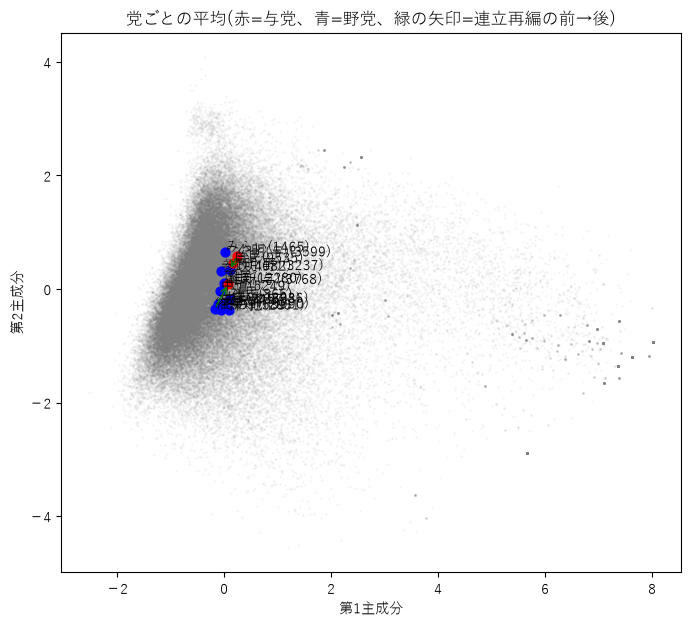

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plt.rcParams["font.family"] = "Yu Gothic"

pca = PCA(n_components=2)
Z = pca.fit_transform(X)
df["pc1"], df["pc2"] = Z[:, 0], Z[:, 1]
print("説明できるばらつきの割合:", pca.explained_variance_ratio_.round(3))

# 公明と維新は、与党の時期と野党の時期を分けて点にする
df["label"] = df["party"]
for p in ["公明", "維新"]:
    m = df["party"] == p
    df.loc[m, "label"] = p + df.loc[m, "gov"].map({True: "(与)", False: "(野)"})

g = df.groupby("label").agg(pc1=("pc1", "mean"), pc2=("pc2", "mean"),
                            n=("pc1", "size"), gov=("gov", "mean")) 

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df["pc1"], df["pc2"], s=1, alpha=0.05, color="gray")
for lab, r, in g.iterrows():
    color = "red" if r["gov"] > 0.5 else "blue"
    ax.scatter(r["pc1"], r["pc2"], color=color, s=40)
    ax.annotate(f"{lab}({int(r['n'])})", (r["pc1"], r["pc2"]), fontsize=10)

# 公明・維新の「前→後」を矢印で結ぶ
for p, before, after in [("公明", "(与)", "(野)"), ("維新", "(野)", "(与)")]:
    a, b = g.loc[p + before], g.loc[p + after]
    ax.annotate(
        "", 
        xy=(b["pc1"], b["pc2"]), 
        xytext=(a["pc1"], a["pc2"]), 
        arrowprops=dict(arrowstyle="->", color="green")
    ) 

ax.set_xlabel("第1主成分"); ax.set_ylabel("第2主成分")
ax.set_title("党ごとの平均(赤=与党、青=野党、緑の矢印=連立再編の前→後)")
Path("../outputs").mkdir(exist_ok=True)
plt.savefig("../outputs/pca_parties.png", dpi=150, bbox_inches="tight")
plt.show() 



In [4]:
out = df[df["pc1"] > 3]
print(len(out), "件")
print(out["party"].value_counts().to_dict())
print(
    "文字数の中央値:", 
    out["text"].str.len().median(), 
    "(全体:", 
    df["text"].str.len().median(), 
    ")"
)
for _, r in out.sample(len(out), random_state=0).iterrows():
    print(f"\n[{r['party']}・{r['nameOfMeeting']}] {r['text'][:150]}")

3521 件
{'立憲': 727, '国民': 528, '自民': 493, '維新': 479, '公明': 398, '共産': 189, '中道': 188, '参政': 145, 'れいわ': 129, 'その他': 127, 'みらい': 58, '保守': 30, '社民': 30}
文字数の中央値: 28.0 (全体: 370.0 )

[公明・地方創生及びデジタル社会の形成等に関する特別委員会] 以上で終わります。ありがとうございました。

[自民・文教科学委員会] 副大臣、いかがでしょうか。聞かせてください。

[保守・法務委員会] それでは終わります。どうも。

[立憲・外交防衛委員会] 大変有り難いお言葉、ありがとうございます。 トップレベルで連絡を取り合ってくださるという理解でよろしいですね。

[自民・政治改革に関する特別委員会] ありがとうございます。 我が党も、一致点を見出すべく、真摯に協議をしてまいります。その思いで臨んでまいります。 以上です。ありがとうございました。

[自民・予算委員会第二分科会] ありがとうございます。 以上で質問を終わります。ありがとうございました。

[公明・厚生労働委員会] ありがとうございました。 いろいろな観点からの御意見をいただきましたので、参考にしたいと思います。 ありがとうございます。終わります。

[公明・財務金融委員会] 終わります。ありがとうございました。

[維新・内閣委員会] 残りはまた今度やりたいと思います。 ありがとうございました。

[その他・内閣委員会] 終わります。

[公明・農林水産委員会] はい。 終わります。ありがとうございました。

[れいわ・内閣委員会] 時間がなくなりました。 御丁寧な御回答、どうもありがとうございました。

[社民・厚生労働委員会] 受け取ってくださるということでよろしいですね。

[立憲・外交防衛委員会] 終わります。ありがとうございました。

[れいわ・総務委員会] 時間になったので終わります。 元上司の湯本局長には質問できなくて申し訳ありませんでした。 以上で終わります。ありがとうございます。

[国民・予算委員会] 終わります。ありがとうございました。

[社民・こども・子育て・若者活躍に関する特別委員会] 御異議ないと認めます。 そ

In [5]:
df["n_char"] = df["text"].str.len()

print(
    "第一主成分と文字数の相関:", 
    round(np.corrcoef(df["pc1"], np.log1p(df["n_char"]))[0, 1], 3)
)
print("右側(pc1>3)の件数:", (df["pc1"] > 3).sum())
print("右側の文字数:", df.loc[df["pc1"] > 3, "n_char"].describe(percentiles=[.5, .9, .99]).round(0).to_dict())

print("\n区切りの長さごとに、除かれる発言")
for th in [30, 50, 80, 100, 150]:
    short = df["n_char"] < th
    print(f"  {th:>3}文字未満: {short.sum():>6}件({short.mean():.1%})"
          f"  うち右側の発言 {(short & (df['pc1'] > 3)).sum()}件")

print("\n100文字未満の発言の、党ごとの割合")
print((df["n_char"] < 100).groupby(df["party"]).mean().round(3).sort_values().to_dict())

第一主成分と文字数の相関: nan
右側(pc1>3)の件数: 3521
右側の文字数: {'count': 3521.0, 'mean': 35.0, 'std': 23.0, 'min': 3.0, '50%': 28.0, '90%': 69.0, '99%': 102.0, 'max': 156.0}

区切りの長さごとに、除かれる発言
   30文字未満:   2565件(2.9%)  うち右側の発言 1879件
   50文字未満:   5014件(5.7%)  うち右側の発言 2697件
   80文字未満:   8662件(9.8%)  うち右側の発言 3338件
  100文字未満:  11104件(12.6%)  うち右側の発言 3482件
  150文字未満:  17091件(19.4%)  うち右側の発言 3520件

100文字未満の発言の、党ごとの割合
{'みらい': 0.057, '参政': 0.077, '公明': 0.099, '国民': 0.104, '自民': 0.104, '維新': 0.11, '中道': 0.121, 'その他': 0.135, '立憲': 0.153, '共産': 0.162, 'れいわ': 0.165, '保守': 0.182, '社民': 0.205}


残った発言: 76907 件
説明できるばらつきの割合: [0.134 0.074]

第一成分との相関係数
  与党かどうか: 0.186
  文字数(対数): -0.113
  日付        : 0.129

第二主成分との相関係数
  与党かどうか: 0.159
  文字数(対数): -0.172
  日付        : 0.01


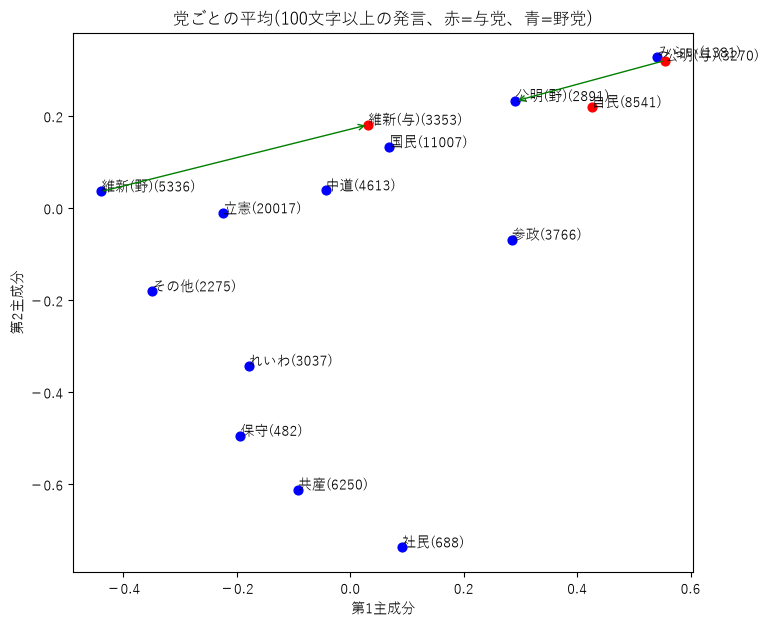

In [6]:
df["n_char"] = df["text"].str.len()
keep = (df["n_char"] >= 100).to_numpy()
d2 = df[keep].reset_index(drop=True)
X2 = X[keep]
print("残った発言:", len(d2), "件")

pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X2)
d2["pc1"], d2["pc2"] = Z2[:, 0], Z2[:, 1]
print("説明できるばらつきの割合:", pca2.explained_variance_ratio_.round(3))

print("\n第一成分との相関係数")
print("  与党かどうか:", round(np.corrcoef(d2["pc1"], d2["gov"])[0, 1], 3))
print("  文字数(対数):", round(np.corrcoef(d2["pc1"], np.log1p(d2["n_char"]))[0, 1], 3))
print("  日付        :", round(np.corrcoef(d2["pc1"], d2["date"].astype("int64"))[0, 1], 3))
print("\n第二主成分との相関係数")
print("  与党かどうか:", round(np.corrcoef(d2["pc2"], d2["gov"])[0, 1], 3))
print("  文字数(対数):", round(np.corrcoef(d2["pc2"], np.log1p(d2["n_char"]))[0, 1], 3))
print("  日付        :", round(np.corrcoef(d2["pc2"], d2["date"].astype("int64"))[0, 1], 3))

g2 = d2.groupby("label").agg(
    pc1=("pc1", "mean"), pc2=("pc2", "mean"),
    n=("pc1", "size"), gov=("gov", "mean")
)
fig, ax = plt.subplots(figsize=(8, 7))
for lab, r in g2.iterrows():
    color = "red" if r["gov"] > 0.5 else "blue"
    ax.scatter(r["pc1"], r["pc2"], color=color, s=40)
    ax.annotate(f"{lab}({int(r['n'])})", (r["pc1"], r["pc2"]), fontsize=10)
for p, before, after in [("公明", "(与)", "(野)"), ("維新", "(野)", "(与)")]:
    a, b = g2.loc[p + before], g2.loc[p + after]
    ax.annotate("", xy=(b["pc1"], b["pc2"]), xytext=(a["pc1"], a["pc2"]), 
                arrowprops=dict(arrowstyle="->", color="green"))
ax.set_xlabel("第1主成分"); ax.set_ylabel("第2主成分")
ax.set_title("党ごとの平均(100文字以上の発言、赤=与党、青=野党)")
Path("../outputs").mkdir(exist_ok=True)
plt.savefig("../outputs/pca_parties_min100.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# (1) 党の違いで、主成分のばらつきの何割を説明できるか
for c in ["pc1", "pc2"]:
    party_mean = d2.groupby("label")[c].transform("mean")
    total = ((d2[c] - d2[c].mean()) ** 2).sum()
    between = ((party_mean - d2[c].mean()) ** 2).sum()
    print(c, "党で説明できる割合:", round(between / total, 3))

# (2) 2025-10-10 の前と後で、党ごとの第1主成分の平均がどれだけ動いたか
d2["after"] = d2["date"] >= "2025-10-10"
t = d2.groupby(["party", "after"])["pc1"].mean().unstack()
t.columns = ["前", "後"]
t["変化"] = t["後"] - t["前"]
t["件数(後)"] = d2[d2["after"]].groupby("party").size()
print(t.round(3).sort_values("変化"))

pc1 党で説明できる割合: 0.082
pc2 党で説明できる割合: 0.115
           前      後     変化  件数(後)
party                            
参政     0.588  0.271 -0.317   3609
公明     0.555  0.291 -0.264   2891
共産    -0.084 -0.105 -0.021   2546
立憲    -0.259 -0.153  0.106   6569
国民    -0.035  0.138  0.172   6614
れいわ   -0.247 -0.042  0.204   1001
その他   -0.441 -0.189  0.253    827
社民    -0.051  0.222  0.273    358
保守    -0.421 -0.085  0.336    326
自民     0.230  0.637  0.407   4101
維新    -0.439  0.031  0.471   3353
みらい      NaN  0.541    NaN   1381
中道       NaN -0.044    NaN   4613


In [8]:
for house in ["衆議院", "参議院"]:
    s = d2[d2["nameOfHouse"] == house]
    m = s.groupby(["party", "after"])["pc1"].mean().unstack()
    n = s.groupby(["party", "after"]).size().unstack()
    t = pd.DataFrame({
        "前": m[False], "後": m[True], "変化": m[True] - m[False], 
        "件数(前)": n[False], "件数(後)": n[True], 
    })
    print(house)
    print(t.round(3).sort_values("変化"))
    print()


衆議院
           前      後     変化   件数(前)   件数(後)
party                                     
参政     0.692  0.400 -0.292   143.0  1643.0
公明     0.659  0.462 -0.197  1399.0   381.0
立憲    -0.245 -0.292 -0.047  8902.0  1846.0
国民     0.140  0.114 -0.026  2463.0  3523.0
共産     0.140  0.219  0.079  1709.0   948.0
その他   -0.712 -0.626  0.086   546.0   331.0
れいわ   -0.285 -0.193  0.092  1331.0   259.0
自民     0.349  0.766  0.417  2580.0  2210.0
維新    -0.314  0.176  0.490  3080.0  1503.0
みらい      NaN  0.558    NaN     NaN  1182.0
中道       NaN -0.048    NaN     NaN  4594.0
保守    -0.421    NaN    NaN   156.0     NaN

参議院
           前      後     変化   件数(前)   件数(後)
party                                     
公明     0.477  0.265 -0.211  1871.0  2504.0
共産    -0.276 -0.297 -0.021  1995.0  1598.0
立憲    -0.282 -0.098  0.184  4522.0  4708.0
れいわ   -0.175  0.010  0.185   705.0   742.0
社民    -0.051  0.222  0.273   330.0   358.0
その他   -0.278  0.103  0.381   902.0   496.0
国民    -0.254  0.167  0.420  1918.0  3078.0
自民

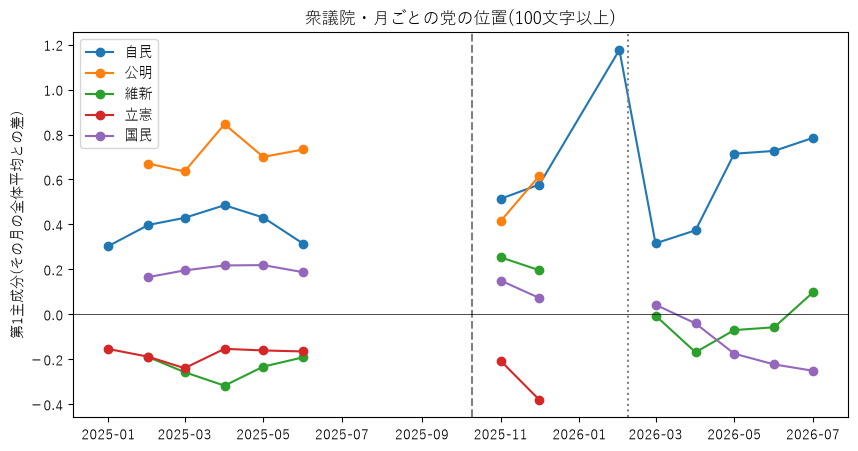

In [9]:
d2h = d2[d2["nameOfHouse"] == "衆議院"].copy()   # 衆議院だけ。d2 はそのまま残る
d2h["month"] = d2h["date"].dt.to_period("M")

monthly_all = d2h.groupby("month")["pc1"].mean()               # その月の全体平均
pm = d2h.groupby(["month", "party"])["pc1"].mean().unstack()   # 月×党の平均
cnt = d2h.groupby(["month", "party"]).size().unstack()         # 月×党の件数
rel = pm.sub(monthly_all, axis=0).where(cnt >= 30)             # 全体平均との差。30件未満は空にする

fig, ax = plt.subplots(figsize=(10, 5))
for p in ["自民", "公明", "維新", "立憲", "国民"]:
    ax.plot(rel.index.to_timestamp(), rel[p], marker="o", label=p)
ax.axvline(pd.Timestamp("2025-10-10"), color="gray", linestyle="--")   # 公明の離脱
ax.axvline(pd.Timestamp("2026-02-08"), color="gray", linestyle=":")    # 衆院選
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel("第1主成分(その月の全体平均との差)")
ax.set_title("衆議院・月ごとの党の位置(100文字以上)")
ax.legend()
plt.savefig("../outputs/pc1_monthly_relative_shu.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
parties = ["自民", "公明", "維新", "立憲", "国民", "中道"]
print(cnt[parties].fillna(0).astype(int))   # 月ごとの件数(信頼できる月かどうか)

gap = pm[parties].sub(pm["自民"], axis=0).where(cnt[parties] >= 30)   # 自民との差
print(gap.drop(columns="自民").round(2))

party     自民   公明    維新    立憲   国民    中道
month                                   
2025-01   45    5    15   123   13     0
2025-02  859  335   559  1953  397     0
2025-03  493  237   504  1374  413     0
2025-04  552  411  1001  2753  791     0
2025-05  405  272   642  1822  545     0
2025-06  213  132   349   827  293     0
2025-08    8    4     6    29    7     0
2025-09    5    3     4    21    4     0
2025-10    0    0     0     0    0     0
2025-11  251  241   167  1247  328     0
2025-12  163  140   119   599  175     0
2026-02   37    0     1     0    2   110
2026-03  259    0   203     0  631   907
2026-04  467    0   348     0  902  1362
2026-05  357    0   278     0  782  1185
2026-06  553    0   279     0  529   792
2026-07  123    0   108     0  174   238
party      公明    維新    立憲    国民    中道
month                                
2025-01   NaN   NaN -0.46   NaN   NaN
2025-02  0.27 -0.59 -0.59 -0.23   NaN
2025-03  0.21 -0.69 -0.67 -0.23   NaN
2025-04  0.36 -0.80 -0.64 -0.27

In [11]:
pd.set_option("display.max_colwidth", 300)

def show_ends(data, party, k=5):
    s = data[data["party"] == party].sort_values("pc1")
    cols = ["date", "nameOfMeeting", "pc1", "text"]
    print(f"===== {party}:pc1 が低い {k} 件 =====")
    for _, r in s.head(k)[cols].iterrows():
        print(r["date"].date(), r["nameOfMeeting"], round(r["pc1"], 2))
        print(r["text"][:250], "\n")
    print(f"===== {party}:pc1 が高い {k} 件 =====")
    for _, r in s.tail(k)[cols].iterrows():
        print(r["date"].date(), r["nameOfMeeting"], round(r["pc1"], 2))
        print(r["text"][:250], "\n")

show_ends(d2h, "自民")
show_ends(d2h, "立憲")


===== 自民:pc1 が低い 5 件 =====
2025-02-27 予算委員会第五分科会 -1.99
やはり施設の中に、介護を分かっている人が専門家にならないと、ほかの分野もみんなそうなんだけれども、ベンダーに丸投げしちゃうから、大体使えないものを作って、使わなくなっちゃうという悪循環ですからね。是非そこを検討してもらいたいというふうに思います。 次に、延命治療についてであります。 これはちょっと私の地元の例を申し上げますけれども、支援者の方がおられて、そのお母さん、百六歳、デイサービスに行っていて、救急車で運ばれた、そうしたら脳溢血だったということでありました。意識がなかったということでありま 

2025-02-27 予算委員会第五分科会 -1.93
喫煙でもあれだけやったんですからね、農水省がやっているところ。だから、省庁を乗り越えてやれるというのは絶対できると思いますので、これはやはり早急な対応が必要だと思います。かなりの数の方が多分苦しんでいるというところでありまして、これは病気ですから、これは病なので、これに対してやはりしっかり対応していかなきゃいけない。それは、私は厚生労働省に是非先頭に立っていただきたいというふうに思っているところでありまして、そのためにはやはり資金が必要ですから、その資金の調達の在り方というのは是非検討いただきた 

2025-04-02 経済産業委員会 -1.88
なるほど、そういうふうな違いがあったんですね。では、新しいものを作ろうとするときに、本当に早く対応して新しいものを作っていくというのは、逆にラピダスなんかの方がいいんじゃないかなんという期待もできるわけだと思います。 本当に、今いろいろ私も一番初めに申し上げましたけれども、今後、世界の産業技術がとてつもなく進んでいって今と全然違う世の中になっていくと思うんですが、そのときにこんな世の中になるんじゃないかみたいな私の想像も申し上げたところでございますけれども、私が今物すごく注目しておりますのがグロ 

2025-05-14 内閣委員会 -1.82
そういったインセンティブを、まさに、先ほどちょっと言ったように、戻ってきたときのポジションを用意するだとか、あと、私、もう一点大事なのが、これが今日のメインのテーマとして考えているんですけれども、宿舎の問題です。 引っ越

In [12]:
PROC = r"緊急動議|付帯決議案|案文の朗読|趣旨の説明に代え"
m = d2["text"].str.contains(PROC)
print("手続きの発言:", m.sum(), "件")
print(d2[m].groupby("party").size().sort_values(ascending=False))

手続きの発言: 0 件
Series([], dtype: int64)


In [13]:
CASUAL = r"でしょう|じゃない|ちゃう|ちゃっ|よね|だって|んです|んだ|けど|みたいな|ちょっと"
d2["casual"] = d2["text"].str.count(CASUAL) / d2["n_char"] * 1000   # 1000文字あたりの回数

print("第1主成分との相関:", round(np.corrcoef(d2["pc1"], d2["casual"])[0, 1], 3))

# 衆議院の維新・国民・自民で、再編の前後に話し方が変わったか
h = d2[d2["nameOfHouse"] == "衆議院"]
print(h[h["party"].isin(["維新", "国民", "自民"])]
      .groupby(["party", "after"])["casual"].mean().unstack().round(2))

第1主成分との相関: -0.621
after  False  True 
party              
国民      4.54   5.19
維新      7.34   4.73
自民      3.17   2.11


In [14]:
from sklearn.linear_model import LinearRegression

Z = np.column_stack([d2["casual"], np.log1p(d2["n_char"])])   # 説明に使う2つ:くだけ度、長さ
lr = LinearRegression().fit(Z, d2["pc1"])
d2["pc1_adj"] = d2["pc1"] - lr.predict(Z)                      # 話し方と長さで説明できる分を引いた残り
print("話し方と長さで説明できる割合:", round(lr.score(Z, d2["pc1"]), 3))

h = d2[d2["nameOfHouse"] == "衆議院"]
t = (h[h["party"].isin(["維新", "国民", "自民"])]
     .groupby(["party", "after"])[["pc1", "pc1_adj"]].mean().unstack().round(2))
print(t)

話し方と長さで説明できる割合: 0.431
        pc1       pc1_adj      
after False True    False True 
party                          
国民     0.14  0.11   -0.02  0.03
維新    -0.31  0.18   -0.22  0.06
自民     0.35  0.77    0.10  0.41


In [15]:
import pandas as pd

q3 = pd.read_parquet("../data/processed/speeches.parquet",
                     columns=["speechID", "date", "nameOfMeeting", "speaker",
                              "speakerGroup", "party", "text", "speechURL"])

# (a) 怪しかった 2025-02-14 予算委員会の「御質問ありがとうございます」
s = q3[(q3["date"] == "2025-02-14") & (q3["nameOfMeeting"] == "予算委員会")
       & q3["text"].str.contains("質問ありがとうございます", na=False)]
print(s[["speaker", "speakerGroup", "party", "speechURL"]].to_string())

# (b) 議員以外がよく使う言い回しを含む発言が、全体で何件あるか
GUEST = r"御質問ありがとうございます|質問ありがとうございます|公述人として|参考人として"
g = q3[q3["text"].str.contains(GUEST, na=False)]
print("\n言い回しを含む発言:", len(g), "件")
print(g.groupby("party").size().sort_values(ascending=False))
print(g.groupby("speaker").size().sort_values(ascending=False).head(15))

Empty DataFrame
Columns: [speaker, speakerGroup, party, speechURL]
Index: []

言い回しを含む発言: 253 件
party
立憲     84
国民     56
自民     29
維新     20
共産     19
公明     15
れいわ    13
中道      6
参政      5
その他     4
みらい     1
保守      1
dtype: int64
speaker
臼木秀剛     14
杉尾秀哉     11
山井和則      7
浜口誠       6
辰巳孝太郎     6
秋野公造      6
橋本幹彦      5
池下卓       5
重徳和彦      5
泉房穂       5
岡本充功      4
打越さく良     4
円より子      4
奥村祥大      4
石垣のりこ     4
dtype: int64


In [16]:
q2 = q3[["date", "speaker", "speakerGroup", "party"]]
print(q2.groupby("party")["date"].agg(["min", "max", "size"]))

f = q2[q2["speaker"].str.contains("福島", na=False)]
print(f.groupby(["speaker", "speakerGroup", "party"])["date"].agg(["min", "max", "size"]))

             min        max   size
party                             
その他   2025-02-03 2026-07-23   2631
みらい   2025-11-25 2026-07-27   1465
れいわ   2025-01-23 2026-07-24   3636
中道    2026-02-18 2026-07-27   5249
保守    2025-02-25 2026-07-16    589
公明    2025-01-23 2026-07-24   6836
共産    2025-01-22 2026-07-27   7457
参政    2025-02-25 2026-07-27   4082
国民    2025-01-23 2026-07-27  12280
社民    2025-03-13 2026-07-16    865
立憲    2025-01-23 2026-07-24  23628
維新    2025-01-23 2026-07-27   9758
自民    2025-01-23 2026-07-27   9535
                                  min        max  size
speaker speakerGroup party                            
福島みずほ   社会民主党        社民    2026-03-31 2026-07-16   224
        立憲民主・社民・無所属  社民    2025-03-13 2026-01-23   186
福島伸享    有志の会         その他   2025-02-07 2025-12-15   227


In [17]:
# (1) 会派ごとに、割り当てた党と、発言者の人数・件数
grp = q2.groupby(["speakerGroup", "party"]).agg(人数=("speaker", "nunique"), 件数=("speaker", "size"))
print(grp.sort_values("件数", ascending=False).to_string())

# (2) 合同会派の発言者の一覧
for gname in ["立憲民主・社民・無所属"]:
    print("\n=====", gname)
    print(q2[q2["speakerGroup"] == gname].groupby("speaker").size().sort_values(ascending=False).to_string())

# (3) みらいの安野貴博議員の発言が、どの会派に入っているか
print(q2[q2["speaker"].str.contains("安野", na=False)]
      .groupby(["speakerGroup", "party"])["date"].agg(["min", "max", "size"]))

                     人数     件数
speakerGroup party            
立憲民主党・無所属    立憲     140  12677
日本維新の会       維新      70   9758
日本共産党        共産      21   7457
自由民主党・無所属の会  自民     319   7210
公明党          公明      52   6836
国民民主党・無所属クラブ 国民      36   6626
立憲民主・社民・無所属  立憲      48   6267
国民民主党・新緑風会   国民      25   5654
中道改革連合・無所属   中道      45   5249
立憲民主・無所属     立憲      38   4684
参政党          参政      32   4082
れいわ新選組       れいわ     16   3636
自由民主党        自民      92   2325
チームみらい       みらい     11   1247
各派に属しない議員    その他     10    934
有志の会         その他      4    743
日本保守党        保守       5    589
沖縄の風         その他      3    531
立憲民主・社民・無所属  社民       3    478
社会民主党        社民       2    387
無所属          その他      6    248
チームみらい・無所属の会 みらい      2    204
ＮＨＫから国民を守る党  その他      2    117
減税保守こども      その他      2     20
改革の会         その他      2     20
ＮＨＫ党         その他      1     18
各派に属しない議員    みらい      1     14

===== 立憲民主・社民・無所属
speaker
村田享子      354
石橋通宏      274
大椿ゆうこ     266
古賀之士      261
塩村あやか     253
川田龍平

In [18]:
EXT = Path("../data/external")

override = pd.DataFrame({
    "speaker": ["福島みずほ", "大椿ゆうこ", "ラサール石井", "安野貴博"],
    "party":   ["社民",       "社民",       "社民",         "みらい"],
    "note":    ["社民党首。2026-01まで会派「立憲民主・社民・無所属」",
                "社民副党首。2025-07任期満了まで同会派",
                "社民。2025-07初当選、2026-01まで同会派",
                "チームみらい党首。2025年は「各派に属しない議員」"],
})
override.to_csv(EXT / "speaker_party_override.csv", index=False, encoding="utf-8")

exclude = pd.DataFrame({
    "speaker": ["山本一太"],
    "reason":  ["公述人(群馬県知事、2025-02-14 衆院予算委員会公聴会)。API が元参院議員の会派を付けていた"],
})
exclude.to_csv(EXT / "speaker_exclude.csv", index=False, encoding="utf-8")

print(pd.read_csv(EXT / "speaker_party_override.csv"))
print(pd.read_csv(EXT / "speaker_exclude.csv"))

  speaker party                           note
0   福島みずほ    社民  社民党首。2026-01まで会派「立憲民主・社民・無所属」
1   大椿ゆうこ    社民         社民副党首。2025-07任期満了まで同会派
2  ラサール石井    社民     社民。2025-07初当選、2026-01まで同会派
3    安野貴博   みらい     チームみらい党首。2025年は「各派に属しない議員」
  speaker                                                reason
0    山本一太  公述人(群馬県知事、2025-02-14 衆院予算委員会公聴会)。API が元参院議員の会派を付けていた


In [ ]:
# 元の会議録をすべて読み込む
rows = []
for p in sorted(Path("../data/raw/kokkai").glob("speech_*.json")):
    rows += json.loads(p.read_text(encoding="utf-8")).get("speechRecord", [])
raw = pd.DataFrame(rows)

# 前の 88,297件にはあって、新しい 88,011件にはない発言 = 今回消えた発言
old_ids = pd.read_csv("../data/embeddings/emb/speech_ids.csv")["speechID"]
new_ids = pd.read_parquet("../data/processed/speeches.parquet", columns=["speechID"])["speechID"]
dropped = raw[raw["speechID"].isin(old_ids) & ~raw["speechID"].isin(new_ids)]
print("消えた発言:", len(dropped), "件")   # 286 のはず(非議員14 + 手続き272)

# そのうち、手続きの言い回しで消えたもの
PROC = r"緊急動議|附帯決議案|案文の朗読|趣旨の説明に代え"
proc = dropped[dropped["speech"].str.contains(PROC, na=False)]
print("\n手続きの発言:", len(proc), "件")
print("文字数の分布:")
print(proc["speech"].str.len().describe().round(0))

# 無作為に10件読む
for t in proc.sample(10, random_state=0)["speech"]:
    print(t[:150], "\n")

消えた発言: 286 件

手続きの発言: 272 件
文字数の分布:
count     272.0
mean     1387.0
std      1035.0
min        85.0
25%       695.0
50%      1165.0
75%      1952.0
max      6838.0
Name: speech, dtype: float64
○福重委員　ただいま議題となりました附帯決議案につきまして、提出者を代表いたしまして、その趣旨を御説明申し上げます。
　趣旨の説明は、案文を朗読して代えさせていただきたいと存じます。
　　　　地域公共交通の活性化及び再生に関する法律の一部を改正する法律案に対する附帯決議（案）
　　政府は、本法 

○谷合正明君　女性皇族や御家族の身分の問題も含まれ得ると示されたところであります。
　それでは、官房長官にこの附則第六条、また附帯決議案についての認識について、同じ質問になりますが、確認をさせてください。 

○塩村あやか君　私は、ただいま可決をされました国家情報会議設置法案に対し、自由民主党・無所属の会、立憲民主・無所属、国民民主党・新緑風会、公明党、日本維新の会及び参政党の各派共同提案による附帯決議案を提出いたします。
　案文を朗読いたします。
 　　　国家情報会議設置法案に対する附帯決議（案）

○鈴木隼人君　請願上程に関する緊急動議を提出いたします。
　本日委員会の審査を終了した裁判所の人的・物的充実に関する請願外五百請願を一括議題とし、その審議を進められることを望みます。
　　　　―――――――――――――
　　　　〔請願の件名は本号末尾に掲載〕
　　　　―――――――――――― 

○梅村みずほ君　私は、ただいま可決されましたポリ塩化ビフェニル廃棄物の適正な処理の推進に関する特別措置法及び中間貯蔵・環境安全事業株式会社法の一部を改正する法律案に対し、自由民主党・無所属の会、立憲民主・無所属、国民民主党・新緑風会、公明党、日本維新の会、参政党、沖縄の風及びチームみらい・無所属の会 

○小寺裕雄君　議事日程追加の緊急動議を提出いたします。
　内閣提出、財政運営に必要な財源の確保を図るための公債の発行の特例に関する法律の一部を改正する法律案、東日本大震災からの復興のための施策を実施する

In [26]:
BROAD  = r"緊急動議|附帯決議案|案文の朗読|趣旨の説明に代え"   # 今のスクリプトのパターン
STRICT = r"緊急動議を提出|趣旨の説明に代え"                  # 手続きの決まり文句だけ

members = dropped[dropped["speaker"] != "山本一太"]
only_broad = members[members["speech"].str.contains(BROAD, na=False)
                     & ~members["speech"].str.contains(STRICT, na=False)]
print("広いパターンだけに当たった発言:", len(only_broad), "件")
for t in only_broad.sample(min(10, len(only_broad)), random_state=0)["speech"]:
    print(t[:200], "\n")

広いパターンだけに当たった発言: 154 件
○三角委員　ただいま議題となりました附帯決議案につきまして、提出者を代表いたしまして、案文を朗読し、趣旨の説明といたします。
　　　　株式会社日本政策投資銀行法の一部を改正する法律案に対する附帯決議（案）
　　政府は、次の事項について、十分配慮すべきである。
　一　株式会社日本政策投資銀行ができる限り早期に完全民営化することとされていること及び特定投資業務が時限を定めて導入されたことを踏まえ 

○石垣のりこ君　私は、ただいま可決されました日本中央競馬会法の一部を改正する法律案に対し、自由民主党・無所属の会、立憲民主・無所属、国民民主党・新緑風会、公明党、日本維新の会、参政党及び日本共産党の各派共同提案による附帯決議案を提出いたします。
　案文を朗読いたします。
　　　　日本中央競馬会法の一部を改正する法律案に対する附帯決議（案）
　　農業構造転換集中対策の実施の財源に充てるため、日 

○岸真紀子君　私は、ただいま可決されました情報通信技術を活用した行政の推進等に関する法律及び情報処理の促進に関する法律の一部を改正する法律案に対し、自由民主党・無所属の会、立憲民主・無所属、国民民主党・新緑風会、公明党、日本維新の会、沖縄の風及びチームみらい・無所属の会の各派共同提案による附帯決議案を提出いたします。
　案文を朗読いたします。
　　　　情報通信技術を活用した行政の推進等に関する 

○打越さく良君　私は、ただいま可決されました出入国管理及び難民認定法及び出入国管理及び難民認定法第二条第五号ロの旅券を所持する外国人の上陸申請の特例に関する法律の一部を改正する法律案に対し、自由民主党・無所属の会、立憲民主・無所属、国民民主党・新緑風会、公明党及び日本維新の会の各派共同提案による附帯決議案を提出いたします。
　案文を朗読いたします。
　　　　出入国管理及び難民認定法及び出入国管 

○塩村あやか君　私は、ただいま可決されました日本国の自衛隊と我が国以外の締約国の軍隊との間における相互のアクセス及び協力の円滑化に関する日本国と我が国以外の締約国との間の協定の実施に関する法律案に対し、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派共同提案による附帯決議案を提出いたします。
　案文を朗読いたし

In [28]:
PROC2 = r"緊急動議を提出|趣旨の説明に代え|趣旨の説明といたします|案文を朗読|案文の朗読|附帯決議案を提出"

rest = members[members["speech"].str.contains(BROAD, na=False)
               & ~members["speech"].str.contains(PROC2, na=False)]
print("手続きの言い回しを含まない発言:", len(rest), "件")
for t in rest["speech"]:
    print(t[:200], "\n")

手続きの言い回しを含まない発言: 19 件
○中川（康）議員　ポスターに関する規制についての指摘につきましては、公営のポスター掲示の在り方については今後の議論の一つであるというふうに私どもも捉えておりますし、この後に議論されます附帯決議案においてもそのことが付されているというふうに承知をいたしております。
　さらには、他の政党の名誉を傷つけるとはどのような範囲かということで、これは事実に基づいてどのように判断するのかということが大事かと思 

○中川（康）議員　法案提出者として答弁させていただきます。
　公営のポスター掲示場につきましては、ポスター掲示場所に関する候補者間の公平の確保、また町の美観の維持、さらには選挙運動費用の節減、一斉に掲示板に貼ることによる選挙人の便宜といった意義がありますので、私としては、上記のような観点から、現段階において一定程度、この公営掲示場の必要性というのはあるものと考えております。
　しかし、公営掲示 

○福島委員　有志の会の福島伸享です。
　私は、衆法第九号及びその附帯決議に反対の立場から討論を行います。
　近年、インターネットを利用した選挙の普及などを背景として、これまででは考えられなかったような公職選挙法の穴を利用した不適切な選挙運動が行われています。言うまでもなく選挙は民主政治の基盤であり、公正な選挙が担保されるためのルールが必要ですが、そもそも政治活動や選挙活動の実態からかけ離れた細 

○長友（よ）委員　ただいま議題となりました附帯決議案につきまして、提出者を代表して、その趣旨を御説明申し上げます。
　趣旨の説明は、案文朗読をもって代えたいと思います。どうぞよろしくお願いいたします。
　　　　道路法等の一部を改正する法律案に対する附帯決議（案）
　　政府は、本法の施行に当たっては、次の諸点に留意し、その運用について遺漏なきを期すべきである。
　一　令和六年能登半島地震によ 

○橋本（慧）委員　立憲民主党・無所属の橋本慧悟です。
　私は、会派を代表して、人工知能関連技術の研究開発及び活用の推進に関する法律案に関し、立憲民主党・無所属及び有志の会提出の修正案に賛成、政府原案に、その課題や懸念を指摘しつつ、賛成の立場から討論をいたします。
　私たち立憲民主党は、ＡＩ技術が我が国の経済社会の発展の基盤となること、国際競争力を向

In [2]:
import json
import pandas as pd
from pathlib import Path

# 元の会議録を読み込む
rows = []
for p in sorted(Path("../data/raw/kokkai").glob("speech_*.json")):
    rows += json.loads(p.read_text(encoding="utf-8")).get("speechRecord", [])
raw = pd.DataFrame(rows)
print("元の会議録:", len(raw), "件")   # 194,567 のはず

# 前の 88,297件にあって、新しい parquet にない発言 = 今回消えた発言
old_ids = pd.read_csv("../data/embeddings/emb/speech_ids.csv")["speechID"]
new_ids = pd.read_parquet("../data/processed/speeches.parquet", columns=["speechID"])["speechID"]
dropped = raw[raw["speechID"].isin(old_ids) & -raw["speechID"].isin(new_ids)]
members = dropped[dropped["speaker"] != "山本一太"]
print("消えた発言:", len(dropped), "件")   # 286 のはず

# 前のパターンには当たらないのに、今のパターンで消えた発言
BROAD = r"緊急動議|附帯決議案|案文の朗読|趣旨の説明に代え"
new_only = members[~members["speech"].str.contains(BROAD, na=False)]
print("新しく消えた発言:", len(new_only), "件\n")
for t in new_only["speech"]:
    print(t[:200], "\n")

元の会議録: 194567 件
消えた発言: 286 件
新しく消えた発言: 18 件

○野田国義君　私は、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派共同提案による自立した安定的な財政運営を実現するための地方税財政制度の構築等に関する決議案を提出いたします。
　案文を朗読させていただきます。
　　　　自立した安定的な財政運営を実現するための地方税財政制度の構築等に関する決議（案）
　　地方公共団体が人口減少の下で疲弊する地域経済の現状 

○田名部匡代君　私は、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派並びに各派に属しない議員寺田静さんの共同提案による新たな食料・農業・農村基本計画に基づく施策の推進に関する決議案を提出いたします。
　案文を朗読いたします。
　　　　新たな食料・農業・農村基本計画に基づく施策の推進に関する決議（案）
　　地球規模での気候変動や国際情勢の不安定化などによ 

○眞野委員　私は、提出者を代表いたしまして、本動議について御説明申し上げます。
　案文を朗読して説明に代えさせていただきます。
　　　　大学等における修学の支援に関する法律の一部を改正する法律案に対する附帯決議（案）
　　政府及び関係者は、本法の施行に当たっては、次の事項について特段の配慮をすべきである。
　一　高等教育の修学支援新制度は、学生等に対する経済的支援の面を持つ一方で、大学等に 

○川田龍平君　ただいま議題となりました自由民主党、立憲民主・社民・無所属、公明党、日本維新の会、国民民主党・新緑風会、日本共産党及び沖縄の風の各派並びに各派に属しない議員鈴木宗男君及び神谷宗幣君の共同提案に係る決議案につきまして、発議者を代表し、提案の趣旨を御説明申し上げます。
　案文を朗読いたします。
　　　　国際協同組合年に当たり協同組合の振興を図る決議案
　　国際連合は、二〇二三年十二 

○日野委員　私は、提出者を代表いたしまして、本動議について御説明申し上げます。
　案文を朗読して説明に代えさせていただきます。
　　　　公立の義務教育諸学校等の教育職員の給与等に関する特別措置法等の一部を改正する法律案に対する附帯決議（案）
　　政府及び関係者は、本法の施行に当たっては、次の事項について特段の配

In [3]:
new_ids = pd.read_parquet("../data/processed/speeches.parquet", columns=["speechID"])["speechID"]
PROC = r"緊急動議を提出|趣旨の説明に代え|趣旨の説明といたします|案文を朗読|案文の朗読|案文朗読|附帯決議案を提出"
kept = raw[raw["speechID"].isin(new_ids)
           & raw["speech"].str.contains(PROC, na=False)]
print("手続きの言い回しを含むが残した発言:", len(kept), "件")
for t in kept["speech"]:
    print(t.split("\n")[0][:100])

手続きの言い回しを含むが残した発言: 4 件
○稲富修二君　立憲民主党・無所属の稲富修二です。
○井坂委員　立憲民主党・無所属の井坂信彦です。
○後藤（祐）委員　私は、会派を代表して、ただいま議題となりました令和八年度一般会計予算、令和八年度特別会計予算及び令和八年度政府関係機関予算につき撤回のうえ編成替えを求めるの動議に関して、その趣旨を御
○中野（洋）委員　私は、会派を代表して、ただいま議題となりました令和八年度一般会計補正予算（第１号）及び令和八年度特別会計補正予算（特第１号）につき撤回のうえ編成替えを求めるの動議に関して、その趣旨を
